In [1]:
import numpy as np
import networkx as nx
from scipy.linalg import eig
from heapq import heappush, heappop
from collections import defaultdict
from tqdm import tqdm
import pandas as pd
import matplotlib.pyplot as plt
import time
import random
from sklearn.metrics import precision_recall_fscore_support, classification_report

# ----------------------------------------------------
# 1. Definición de los 3 Kernels de Proyección en LSH
# ----------------------------------------------------

def projection_frobenius(A, B):
    # Producto interno de Frobenius literal (traza de A.T @ B)
    return np.trace(np.dot(A.T, B))


def projection_random_walk(A, B):
    # Kernel de caminatas aleatorias de p-pasos (p=3, beta=0.05)
    p = 3
    beta = 0.05
    N = A.shape[0]
    
    val = float(N)
    A_k = np.eye(N)
    B_k = np.eye(N)
    
    for k in range(1, p + 1):
        A_k = np.dot(A_k, A)
        B_k = np.dot(B_k, B)
        val += (beta ** k) * np.sum(A_k) * np.sum(B_k)
        
    return val


def projection_shortest_path(A, B):
    # Kernel de caminos más cortos (Shortest Path Graph Kernel, unweighted)
    from scipy.sparse.csgraph import shortest_path
    
    DA = shortest_path(A, directed=False, unweighted=True)
    DB = shortest_path(B, directed=False, unweighted=True)
    
    DA[np.isinf(DA)] = 99.0
    DB[np.isinf(DB)] = 99.0
    
    gamma = 0.5
    val = np.sum(np.exp(-gamma * np.abs(DA - DB)))
    return float(val)

# Alias para compatibilidad hacia atrás
matrix_prod_trace = projection_frobenius

# ----------------------------------------------------
# 2. Funciones Base de Clustering Ponderado (Suma Directa)
# ----------------------------------------------------

def get_graph(edges, nodes):
    g = nx.Graph()
    g.add_edges_from(edges)
    g.add_nodes_from(nodes)
    return g


def hash_p_stable(projection, r):
    if r <= 0:
        return 0
    b = np.random.uniform(0, r)
    return int(np.floor((projection + b) / r))


def get_erdos_renyi_graph(n, p):
    while True:
        g = nx.erdos_renyi_graph(n, p)
        if g.number_of_edges() > 0:
            return g


def get_adjacency(g, N):
    if 'adjacency' in g.graph:
        return g.graph['adjacency']

    g_copy = g.copy()
    g_copy.remove_edges_from(nx.selfloop_edges(g_copy))

    nodes_order = list(sorted(g_copy.nodes()))

    A = nx.adjacency_matrix(
        g_copy,
        nodelist=nodes_order,
        weight='weight'
    ).toarray().astype(float)

    M = A.shape[0]
    A = np.pad(A, [(0, N - M), (0, N - M)], mode="constant")

    if not g.graph.get('is_merged', False):
        A = (A > 0).astype(float)

    np.fill_diagonal(A, 0)
    g.graph['adjacency'] = A
    return A


def get_density_matrix(A):
    num_edges = np.sum(A) / 2.0
    if num_edges == 0:
        return np.zeros_like(A)
    degrees = np.sum(A, axis=1)
    L = np.diag(degrees) - A
    return L / (2.0 * num_edges)


def entropy_from_rho(rho):
    eigvals = np.linalg.eigvalsh(rho)
    eigvals[eigvals < 1e-12] = 0.0
    eigvals = eigvals[eigvals > 1e-12]
    return float(-np.sum(eigvals * np.log2(eigvals)))


def von_newmann_entropy(g):
    if 'vn_entropy' in g.graph:
        return g.graph['vn_entropy']

    A = get_adjacency(g, 10)
    rho = get_density_matrix(A)
    entropy = entropy_from_rho(rho)
    
    g.graph['vn_entropy'] = entropy
    g.graph['rho'] = rho
    return entropy


def get_rho(g, N):
    if 'rho' in g.graph:
        return g.graph['rho']
    A = get_adjacency(g, N)
    rho = get_density_matrix(A)
    g.graph['rho'] = rho
    return rho


def aggregate(g1, g2, N):
    A1 = get_adjacency(g1, N)
    A2 = get_adjacency(g2, N)

    A = A1 + A2
    np.fill_diagonal(A, 0)
    
    g = nx.from_numpy_array(A)
    g.graph['is_merged'] = True
    return g


def js_divergence(g1, g2, N):
    rho1 = get_rho(g1, N)
    rho2 = get_rho(g2, N)

    # Mezcla 50/50 de las matrices de densidad
    rho_mix = (rho1 + rho2) / 2.0

    h_mix = entropy_from_rho(rho_mix)
    h_avg = (von_newmann_entropy(g1) + von_newmann_entropy(g2)) / 2.0
    val = max(h_mix - h_avg, 0.0)
    return np.sqrt(val)


def get_bucket_id_for_graph(g, random_graphs, B, projection_ranges, N_pad, proj_func):
    bucket_id = ""
    A = get_adjacency(g, N_pad)

    for k, erg in enumerate(random_graphs):
        A_er = get_adjacency(erg, N_pad)
        proj = proj_func(A, A_er)

        min_proj, max_proj = projection_ranges[k]
        r = (max_proj - min_proj) / B

        hash_bin = hash_p_stable(proj, r)
        bucket_id += f"{hash_bin}_"

    return bucket_id


def aggregate_many(graph_list, N):
    A_union = np.zeros((N, N))
    for g in graph_list:
        A_union += get_adjacency(g, N)

    np.fill_diagonal(A_union, 0)

    g = nx.from_numpy_array(A_union)
    g.graph['is_merged'] = True
    return g


def quality(active, clusters, h_total=None, N_pad=None):
    active = list(active)
    if len(active) == 0:
        return 0.0

    if N_pad is None:
        N_pad = max(g.number_of_nodes() for g in clusters.values())

    active_graphs = [clusters[i] for i in active]

    if h_total is None:
        active_rhos = [get_rho(g, N_pad) for g in active_graphs]
        rho_total = np.mean(active_rhos, axis=0)
        h_total = entropy_from_rho(rho_total)

    if h_total <= 1e-12:
        return 0.0

    H_C = np.mean([
        von_newmann_entropy(g)
        for g in active_graphs
    ])

    q = 1.0 - (H_C / h_total)
    return float(q)


def refill_heap_global(active, clusters, N_pad):
    heap = []
    active_list = list(active)

    for a in range(len(active_list)):
        for b in range(a + 1, len(active_list)):
            i = active_list[a]
            j = active_list[b]

            dist = js_divergence(clusters[i], clusters[j], N_pad)
            heappush(heap, (dist, i, j))

    return heap


def has_bucket_candidates(bucket_members, active):
    for members in bucket_members.values():
        alive = [x for x in members if x in active]
        if len(alive) >= 2:
            return True
    return False


In [2]:
edges_file = "data/FAO_Multiplex_Trade/Dataset/fao_trade_multiplex.edges"
layers_file = "data/FAO_Multiplex_Trade/Dataset/fao_trade_layers.txt"

layer_labels = {}
with open(layers_file, 'r') as f:
    next(f) # skip header
    for line in f:
        parts = line.strip().split()
        if len(parts) >= 2:
            layer_labels[int(parts[0])] = parts[1]

MAX_LAYERS = len(layer_labels)
fao_graphs = {i: nx.Graph() for i in range(1, MAX_LAYERS + 1)}

with open(edges_file, 'r') as f:
    for line in f:
        parts = line.strip().split()
        layer_id = int(parts[0])
        if layer_id <= MAX_LAYERS:
            u, v, w = int(parts[1]), int(parts[2]), float(parts[3])
            # Llenamos la red insertando aristas. 
            fao_graphs[layer_id].add_edge(u, v, weight=w)

graphs_fao = [fao_graphs[i] for i in range(1, MAX_LAYERS + 1) if fao_graphs[i].number_of_edges() > 0]
# Generamos un label real para los nodos de hojas si quisiéramos
labels_fao = [layer_labels.get(i, f"L{i}") for i in range(1, MAX_LAYERS + 1) if fao_graphs[i].number_of_edges() > 0]

print(f"Gráficos cargados y válidos: {len(graphs_fao)} capas seleccionadas.")

Gráficos cargados y válidos: 364 capas seleccionadas.


In [3]:
graphs = graphs_fao

N_pad = max(g.number_of_nodes() for g in graphs)

In [4]:
N_pad

207

In [5]:
def build_lsh_buckets(graphs, num_proj=10, B=40, p_er=0.8):
    num_graphs = len(graphs)
    N_pad = max(g.number_of_nodes() for g in graphs)

    bucket_ids = [""] * num_graphs
    random_graphs = []
    projection_ranges = []

    for k in tqdm(range(num_proj), desc="LSH projections"):
        erg = get_erdos_renyi_graph(N_pad, p_er)
        random_graphs.append(erg)

        A_er = get_adjacency(erg, N_pad)

        projections = []

        for g in graphs:
            A = get_adjacency(g, N_pad)
            proj = matrix_prod_trace(A, A_er)
            projections.append(proj)

        min_proj = min(projections)
        max_proj = max(projections)

        projection_ranges.append((min_proj, max_proj))

        r = (max_proj - min_proj) / B

        for i in range(num_graphs):
            hash_bin = hash_p_stable(projections[i], r)
            bucket_ids[i] += f"{hash_bin}_"

    buckets = defaultdict(list)

    for i, bid in enumerate(bucket_ids):
        buckets[bid].append(i)

    return buckets, bucket_ids, random_graphs, projection_ranges

In [6]:
def hierarchical_bucket_heap_dynamic(
    graphs,
    buckets,
    bucket_ids,
    random_graphs,
    projection_ranges,
    B,
    proj_func=projection_frobenius,
    epsilon=np.inf
):
    num_graphs = len(graphs)
    N_pad = max(g.number_of_nodes() for g in graphs)

    active = set(range(num_graphs))
    clusters = {i: graphs[i] for i in range(num_graphs)}
    cluster_bucket = {i: bucket_ids[i] for i in range(num_graphs)}

    bucket_members = defaultdict(set)
    for bid, indices in buckets.items():
        bucket_members[bid].update(indices)

    # h_total basado en promedio de matrices de densidad de todos los grafos activos
    active_rhos = [get_rho(clusters[i], N_pad) for i in active]
    rho_total = np.mean(active_rhos, axis=0)
    h_total = entropy_from_rho(rho_total)
    
    heap = []
    for bid, members in bucket_members.items():
        members = list(members)
        for a in range(len(members)):
            for b in range(a + 1, len(members)):
                i = members[a]
                j = members[b]
                dist = js_divergence(clusters[i], clusters[j], N_pad)
                heappush(heap, (dist, i, j))

    Z = []
    next_cluster_id = num_graphs
    global_mode = False

    while len(active) > 1:
        if not global_mode and not has_bucket_candidates(bucket_members, active):
            global_mode = True
            heap = refill_heap_global(active, clusters, N_pad)

        if len(heap) == 0:
            if global_mode:
                heap = refill_heap_global(active, clusters, N_pad)
            else:
                break

        dist, i, j = heappop(heap)
        if i not in active or j not in active:
            continue

        if not global_mode and cluster_bucket[i] != cluster_bucket[j]:
            continue

        if dist > epsilon:
            break

        same_bucket = cluster_bucket[i] == cluster_bucket[j]
        old_bucket_i = cluster_bucket[i]
        old_bucket_j = cluster_bucket[j]

        new_id = next_cluster_id
        next_cluster_id += 1

        new_graph = aggregate(clusters[i], clusters[j], N_pad)

        active.remove(i)
        active.remove(j)
        bucket_members[old_bucket_i].discard(i)
        bucket_members[old_bucket_j].discard(j)

        clusters[new_id] = new_graph
        active.add(new_id)

        new_bucket_id = get_bucket_id_for_graph(
            new_graph,
            random_graphs=random_graphs,
            B=B,
            projection_ranges=projection_ranges,
            N_pad=N_pad,
            proj_func=proj_func
        )
        cluster_bucket[new_id] = new_bucket_id
        bucket_members[new_bucket_id].add(new_id)

        # Recalcular h_total
        active_rhos = [get_rho(clusters[x], N_pad) for x in active]
        rho_total = np.mean(active_rhos, axis=0)
        h_total = entropy_from_rho(rho_total)

        q = quality(active=active, clusters=clusters, h_total=h_total, N_pad=N_pad)
        Z.append([i, j, dist, q, new_id, new_bucket_id, same_bucket, global_mode])

        if global_mode:
            for other in list(active):
                if other == new_id:
                    continue
                new_dist = js_divergence(clusters[new_id], clusters[other], N_pad)
                heappush(heap, (new_dist, new_id, other))
        else:
            for other in list(bucket_members[new_bucket_id]):
                if other == new_id or other not in active:
                    continue
                new_dist = js_divergence(clusters[new_id], clusters[other], N_pad)
                heappush(heap, (new_dist, new_id, other))

    return Z, clusters, active, bucket_members


In [7]:
def shclust_heap_dynamic(graphs, num_proj=10, B=40, epsilon=np.inf):
    buckets, bucket_ids, random_graphs, projection_ranges = build_lsh_buckets(
        graphs,
        num_proj=num_proj,
        B=B
    )

    Z, clusters, active, bucket_members = hierarchical_bucket_heap_dynamic(
        graphs=graphs,
        buckets=buckets,
        bucket_ids=bucket_ids,
        random_graphs=random_graphs,
        projection_ranges=projection_ranges,
        B=B,
        epsilon=epsilon
    )

    return Z, clusters, active, bucket_members, bucket_ids

In [8]:
# Ejecutar LSH para diferentes valores de B

# Set random seeds for reproducibility
np.random.seed(42)
random.seed(42)
B_values = [10, 40, 80, 300]
Z_lsh_dict = {}
time_lsh_dict = {}
num_buckets_dict = {}

for B in B_values:
    print(f"Ejecutando algoritmo LSH con B = {B}...")
    start = time.time()
    Z_B, _, _, _, bucket_ids_B = shclust_heap_dynamic(
        graphs,
        num_proj=5,
        B=B,
        epsilon=np.inf
    )
    time_lsh_dict[B] = time.time() - start
    Z_lsh_dict[B] = Z_B
    num_buckets_dict[B] = len(set(bucket_ids_B))
    print(f"LSH B={B} terminado en {time_lsh_dict[B]:.2f} segundos. Buckets únicos: {num_buckets_dict[B]}")


Ejecutando algoritmo LSH con B = 10...


LSH projections: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:03<00:00,  1.61it/s]


LSH B=10 terminado en 57.44 segundos. Buckets únicos: 112
Ejecutando algoritmo LSH con B = 40...


LSH projections: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00,  5.07it/s]


LSH B=40 terminado en 120.99 segundos. Buckets únicos: 200
Ejecutando algoritmo LSH con B = 80...


LSH projections: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00,  5.66it/s]


LSH B=80 terminado en 169.03 segundos. Buckets únicos: 264
Ejecutando algoritmo LSH con B = 300...


LSH projections: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00,  5.31it/s]


LSH B=300 terminado en 274.74 segundos. Buckets únicos: 349


In [9]:
#Z

In [10]:
def plot_quality_by_merge(Z):
    df = pd.DataFrame(
        Z,
        columns=[
            "cluster_i",
            "cluster_j",
            "dist",
            "q",
            "new_cluster_id",
            "new_bucket_id",
            "same_bucket",
            "global_mode"
        ]
    )

    df["merge"] = range(1, len(df) + 1)

    # Encontrar máximo
    idx_max = df.shape[0] - df["q"].idxmax()
    x_max = df.loc[idx_max, "merge"]
    y_max = df.loc[idx_max, "q"]

    plt.figure(figsize=(8, 5))

    # Línea continua
    plt.plot(df["merge"], df["q"], color="black", linestyle="-")

    # Punto en el máximo
    plt.scatter(x_max, y_max, color="black" , zorder=5)

    #plt.xlabel("Merge")
    plt.ylabel("q(C)")
    #plt.title("Quality q(C) - hierarchical clustering normal")
    plt.grid(True)

    # # Opcional: anotar el punto máximo
    # plt.annotate(
    #     f"max={y_max:.3f}",
    #     (x_max, y_max),
    #     textcoords="offset points",
    #     xytext=(5,5)
    # )

    plt.show()

    return df

# General

In [11]:
def hierarchical_clustering_heap(graphs, epsilon=np.inf):
    num_graphs = len(graphs)
    N_pad = max(g.number_of_nodes() for g in graphs)

    active = set(range(num_graphs))
    clusters = {i: graphs[i] for i in range(num_graphs)}

    active_rhos = [get_rho(clusters[i], N_pad) for i in active]
    rho_total = np.mean(active_rhos, axis=0)
    h_total = entropy_from_rho(rho_total)

    heap = []
    active_list = list(active)
    for a in tqdm(range(len(active_list)), desc="Inicializando heap"):
        for b in range(a + 1, len(active_list)):
            i = active_list[a]
            j = active_list[b]
            dist = js_divergence(clusters[i], clusters[j], N_pad)
            heappush(heap, (dist, i, j))

    Z = []
    next_cluster_id = num_graphs

    while len(active) > 1 and len(heap) > 0:
        dist, i, j = heappop(heap)
        if i not in active or j not in active:
            continue

        if dist > epsilon:
            break

        new_id = next_cluster_id
        next_cluster_id += 1

        new_graph = aggregate(clusters[i], clusters[j], N_pad)
        active.remove(i)
        active.remove(j)

        clusters[new_id] = new_graph
        active.add(new_id)

        # Recalcular h_total
        active_rhos = [get_rho(clusters[x], N_pad) for x in active]
        rho_total = np.mean(active_rhos, axis=0)
        h_total = entropy_from_rho(rho_total)

        q = quality(active=active, clusters=clusters, h_total=h_total, N_pad=N_pad)
        Z.append([i, j, dist, q, new_id])

        for other in list(active):
            if other == new_id:
                continue
            new_dist = js_divergence(clusters[new_id], clusters[other], N_pad)
            heappush(heap, (new_dist, new_id, other))

    return Z, clusters, active


In [12]:
print("Ejecutando clustering jerárquico normal (baseline)...")
start = time.time()
Z_normal, clusters_normal, active_normal = hierarchical_clustering_heap(
    graphs,
    epsilon=np.inf
)
time_normal = time.time() - start
print(f"Clustering normal terminado en {time_normal:.2f} segundos.")


Ejecutando clustering jerárquico normal (baseline)...


Inicializando heap: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 364/364 [02:11<00:00,  2.78it/s]


Clustering normal terminado en 296.43 segundos.


In [13]:

# print("\nMerges:")
# for row in Z_normal:
#     print(row)

# print("\nFinal clusters:")
# print(clusters_normal)

In [14]:
def plot_quality_normal(Z_normal):
    df = pd.DataFrame(
        Z_normal,
        columns=[
            "cluster_i",
            "cluster_j",
            "dist",
            "q",
            "new_cluster_id"
        ]
    )

    df["merge"] = range(1, len(df) + 1)

    # Encontrar máximo
    idx_max = df.shape[0] - df["q"].idxmax()
    x_max = df.loc[idx_max, "merge"]
    y_max = df.loc[idx_max, "q"]

    plt.figure(figsize=(8, 5))

    # Línea continua
    plt.plot(df["merge"], df["q"], color="black", linestyle="-")

    # Punto en el máximo
    plt.scatter(x_max, y_max, color="black" , zorder=5)

    #plt.xlabel("Merge")
    plt.ylabel("q(C)")
    #plt.title("Quality q(C) - hierarchical clustering normal")
    plt.grid(True)

    # # Opcional: anotar el punto máximo
    # plt.annotate(
    #     f"max={y_max:.3f}",
    #     (x_max, y_max),
    #     textcoords="offset points",
    #     xytext=(5,5)
    # )

    plt.show()

    return df

In [15]:
def elbow_method(q):
    """
    Método del codo basado en distancia perpendicular a la recta
    entre (1, q(1)) y (m, q(m)).
    """
    q = np.asarray(q, dtype=float)
    m = len(q)

    x1, y1 = 1, q[0]
    x2, y2 = m, q[-1]

    dx = x2 - x1
    dy = y2 - y1

    norm = np.sqrt(dx**2 + dy**2)

    distances = np.zeros(m)
    for i in range(m):
        x0 = i + 1
        y0 = q[i]
        area = abs(dy * (x0 - x1) - dx * (y0 - y1))
        distances[i] = area / norm

    k_star = int(np.argmax(distances) + 1)
    return k_star, distances


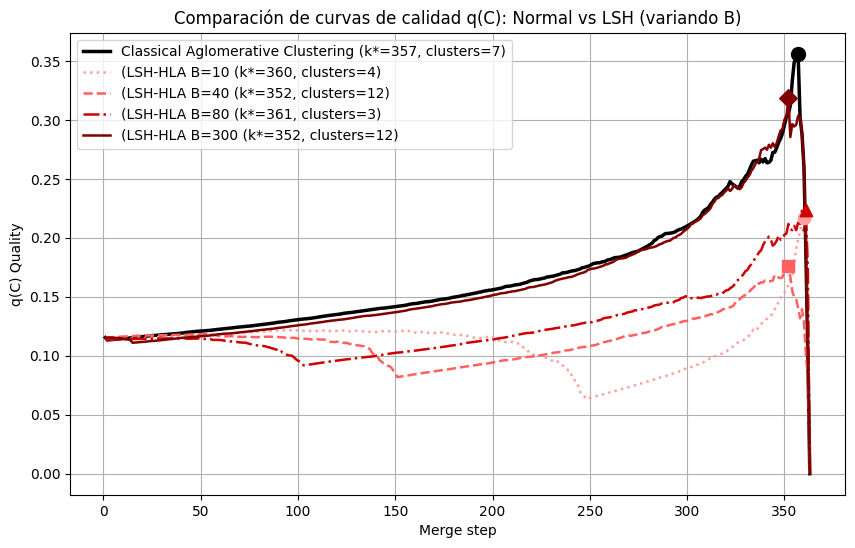


Tabla de resultados del método del codo (Elbow Method):
           Método   B Buckets Únicos  Paso de Fusión (k*)  Cant. Clusters Óptima Tiempo (s)
Normal (Baseline)   -              -                  357                      7     296.43
              LSH  10            112                  360                      4      57.44
              LSH  40            200                  352                     12     120.99
              LSH  80            264                  361                      3     169.03
              LSH 300            349                  352                     12     274.74
Clusters normales guardados en 'clusters_normal.txt'
Clusters LSH (B=10) guardados en 'clusters_lsh_B10.txt'
Clusters LSH (B=40) guardados en 'clusters_lsh_B40.txt'
Clusters LSH (B=80) guardados en 'clusters_lsh_B80.txt'
Clusters LSH (B=300) guardados en 'clusters_lsh_B300.txt'


In [16]:
# 1. Analizar clustering normal
df_normal = pd.DataFrame(
    Z_normal,
    columns=["cluster_i", "cluster_j", "dist", "q", "new_cluster_id"]
)
df_normal["merge"] = range(1, len(df_normal) + 1)

k_star_normal, _ = elbow_method(df_normal["q"].values)
num_cluster_normal = df_normal.shape[0] - k_star_normal + 1

# 2. Analizar y graficar curvas LSH
plt.figure(figsize=(10, 6))

# Graficar curva normal en negro
plt.plot(df_normal["merge"], df_normal["q"], color="black", linestyle="-", linewidth=2.5,
         label=f"Classical Aglomerative Clustering (k*={k_star_normal}, clusters={num_cluster_normal})")
plt.scatter(k_star_normal, df_normal.loc[k_star_normal - 1, "q"], color="black", marker="o", s=100, zorder=5)

# Graficar curvas LSH en diferentes estilos de rojo
red_styles = {
    10: ("#ffa0a0", ":", "o"),      # Rojo claro, punteado, círculo
    40: ("#ff6060", "--", "s"),     # Rojo medio, discontinuo, cuadrado
    80: ("#d00000", "-.", "^"),     # Rojo oscuro, punto-guión, triángulo
    300: ("#800000", "-", "D")      # Rojo muy oscuro, continuo, diamante
}

# Tabla de resultados con columna de Buckets Únicos y Tiempo de Ejecución
resultados = []
resultados.append({
    "Método": "Normal (Baseline)",
    "B": "-",
    "Buckets Únicos": "-",
    "Paso de Fusión (k*)": k_star_normal,
    "Cant. Clusters Óptima": num_cluster_normal,
    "Tiempo (s)": f"{time_normal:.2f}"
})

for B in B_values:
    Z_B = Z_lsh_dict[B]
    df_B = pd.DataFrame(
        Z_B,
        columns=[
            "cluster_i", "cluster_j", "dist", "q", "new_cluster_id",
            "new_bucket_id", "same_bucket", "global_mode"
        ]
    )
    df_B["merge"] = range(1, len(df_B) + 1)
    
    k_star_B, _ = elbow_method(df_B["q"].values)
    num_cluster_B = df_B.shape[0] - k_star_B + 1
    
    resultados.append({
        "Método": "LSH",
        "B": B,
        "Buckets Únicos": num_buckets_dict[B],
        "Paso de Fusión (k*)": k_star_B,
        "Cant. Clusters Óptima": num_cluster_B,
        "Tiempo (s)": f"{time_lsh_dict[B]:.2f}"
    })
    
    color, style, marker = red_styles[B]
    plt.plot(df_B["merge"], df_B["q"], color=color, linestyle=style, linewidth=1.8,
             label=f"(LSH-HLA B={B} (k*={k_star_B}, clusters={num_cluster_B})")
    
    # Marcar el punto del codo en la curva LSH
    plt.scatter(k_star_B, df_B.loc[k_star_B - 1, "q"], color=color, marker=marker, s=80, zorder=5)

plt.xlabel("Merge step")
plt.ylabel("q(C) Quality")
plt.title("Comparación de curvas de calidad q(C): Normal vs LSH (variando B)")
plt.legend()
plt.grid(True)
plt.show()

# Mostrar la tabla de resultados resumidos
df_res = pd.DataFrame(resultados)
print("\nTabla de resultados del método del codo (Elbow Method):")
print(df_res.to_string(index=False))

# -------------------------------------------------------------
# Funciones para reconstruir y guardar la membresía de clusters
# -------------------------------------------------------------

def get_cluster_memberships(Z, num_graphs, target_merges):
    memberships = {i: [i] for i in range(num_graphs)}
    active = set(range(num_graphs))
    
    for step in range(min(target_merges, len(Z))):
        row = Z[step]
        c_i = int(row[0])
        c_j = int(row[1])
        new_id = int(row[4])
        
        memberships[new_id] = memberships[c_i] + memberships[c_j]
        active.remove(c_i)
        active.remove(c_j)
        active.add(new_id)
        
    return {c: memberships[c] for c in active}

def save_clusters_to_file(Z, num_graphs, k_star, labels, filename):
    cluster_members = get_cluster_memberships(Z, num_graphs, k_star)
    
    with open(filename, "w", encoding="utf-8") as f:
        f.write(f"=== CLUSTERING RESULTS ===\n")
        f.write(f"Archivo: {filename}\n")
        f.write(f"Numero de clusters: {len(cluster_members)}\n")
        f.write(f"Paso de fusion (k*): {k_star}\n\n")
        
        # Ordenar clusters de mayor a menor tamaño
        sorted_clusters = sorted(cluster_members.items(), key=lambda x: len(x[1]), reverse=True)
        for idx, (c_id, members) in enumerate(sorted_clusters):
            f.write(f"Cluster {idx + 1} (ID original: {c_id}, Tamano: {len(members)}):\n")
            for m in sorted(members):
                label = labels[m] if m < len(labels) else f"Layer {m}"
                f.write(f"  - [{m}] {label}\n")
            f.write("\n")

# Guardar clusters de la ejecución normal
num_graphs = len(graphs)
save_clusters_to_file(Z_normal, num_graphs, k_star_normal, labels_fao, "clusters_normal.txt")
print("Clusters normales guardados en 'clusters_normal.txt'")

# Guardar clusters de las ejecuciones LSH
for B in B_values:
    Z_B = Z_lsh_dict[B]
    df_B = pd.DataFrame(
        Z_B,
        columns=[
            "cluster_i", "cluster_j", "dist", "q", "new_cluster_id",
            "new_bucket_id", "same_bucket", "global_mode"
        ]
    )
    k_star_B, _ = elbow_method(df_B["q"].values)
    
    filename_lsh = f"clusters_lsh_B{B}.txt"
    save_clusters_to_file(Z_B, num_graphs, k_star_B, labels_fao, filename_lsh)
    print(f"Clusters LSH (B={B}) guardados en '{filename_lsh}'")


## 4. Análisis de Estabilidad y Sensibilidad (10 ejecuciones por parámetro)
Evaluamos el rendimiento robusto del algoritmo LSH-HLA sobre la red FAO multiplex midiendo de forma estadística las siguientes variables clave de la ejecución:
1. **Buckets Únicos:** Cantidad de recipientes LSH distintos generados para las proyecciones.
2. **Paso de Fusión ($k^*$):** El paso de codo de la curva de calidad determinado por el método del codo.
3. **Cant. Clusters Óptima:** Número de agrupamientos resultantes al cortar la jerarquía en $k^*$.
4. **Tiempo ($s$):** Duración total de la corrida en segundos.

Se realizan 10 corridas independientes por cada configuración (con semillas prefijadas para asegurar reproducibilidad), calculando la **media, desviación estándar y moda**.


In [17]:
from collections import Counter

def calculate_mode(values):
    # Redondear a 2 decimales si son flotantes, de lo contrario tomar enteros
    rounded_vals = [round(v, 2) if isinstance(v, float) else v for v in values]
    counts = Counter(rounded_vals)
    mode_val, _ = counts.most_common(1)[0]
    return mode_val


In [ ]:
NUM_RUNS_FAO = 10
NUM_PROJ_FIXED_FAO = 5
B_FIXED_FAO = 40
num_graphs_fao = len(graphs)

# ----------------------------------------------------
# 1.1. Estabilidad de LSH-HLA sobre FAO
# ----------------------------------------------------
print(f"Ejecutando {NUM_RUNS_FAO} corridas de LSH-HLA sobre FAO...")
run_data_fao_lsh = []
np.random.seed(42)
random.seed(42)

for r in tqdm(range(NUM_RUNS_FAO), desc="Corridas LSH"):
    start_time = time.time()
    Z_B, _, _, _, bucket_ids = shclust_heap_dynamic(
        graphs,
        num_proj=NUM_PROJ_FIXED_FAO,
        B=B_FIXED_FAO,
        epsilon=np.inf
    )
    elapsed = time.time() - start_time
    
    # Calcular paso de codo y número de clusters
    df_B = pd.DataFrame(
        Z_B,
        columns=[
            "cluster_i", "cluster_j", "dist", "q", "new_cluster_id",
            "new_bucket_id", "same_bucket", "global_mode"
        ]
    )
    k_star, _ = elbow_method(df_B["q"].values)
    num_clusters = df_B.shape[0] - k_star + 1
    unique_buckets = len(set(bucket_ids))
    
    run_data_fao_lsh.append({
        "Corrida": r + 1,
        "Buckets Únicos": unique_buckets,
        "Paso de Fusión (k*)": k_star,
        "Cant. Clusters Óptima": num_clusters,
        "Tiempo (seg)": elapsed
    })

df_stability_fao_lsh = pd.DataFrame(run_data_fao_lsh)
print("\n=== ESTABILIDAD DE LSH-HLA SOBRE FAO (10 Corridas) ===")
print(df_stability_fao_lsh.to_string(index=False))

print("\n=== ESTADÍSTICAS GLOBALES LSH-HLA SOBRE FAO (Media ± Desv. Estándar) ===")
stats_summary_fao_lsh = pd.DataFrame({
    "Métrica": ["Buckets Únicos", "Paso de Fusión (k*)", "Cant. Clusters Óptima", "Tiempo (seg)"],
    "Promedio": [
        df_stability_fao_lsh["Buckets Únicos"].mean(),
        df_stability_fao_lsh["Paso de Fusión (k*)"].mean(),
        df_stability_fao_lsh["Cant. Clusters Óptima"].mean(),
        df_stability_fao_lsh["Tiempo (seg)"].mean()
    ],
    "Desv. Estándar": [
        df_stability_fao_lsh["Buckets Únicos"].std(),
        df_stability_fao_lsh["Paso de Fusión (k*)"].std(),
        df_stability_fao_lsh["Cant. Clusters Óptima"].std(),
        df_stability_fao_lsh["Tiempo (seg)"].std()
    ],
    "Moda": [
        calculate_mode(df_stability_fao_lsh["Buckets Únicos"].values),
        calculate_mode(df_stability_fao_lsh["Paso de Fusión (k*)"].values),
        calculate_mode(df_stability_fao_lsh["Cant. Clusters Óptima"].values),
        calculate_mode(df_stability_fao_lsh["Tiempo (seg)"].values)
    ]
})
print(stats_summary_fao_lsh.to_string(index=False))

# ----------------------------------------------------
# 1.2. Estabilidad del Baseline sobre FAO (10 Corridas)
# ----------------------------------------------------
print(f"\nEjecutando {NUM_RUNS_FAO} corridas del Baseline (sin LSH) sobre FAO...")
run_data_fao_base = []

for r in tqdm(range(NUM_RUNS_FAO), desc="Corridas Baseline"):
    start_time = time.time()
    Z_base, _, _ = hierarchical_clustering_heap(graphs, epsilon=np.inf)
    elapsed = time.time() - start_time
    
    df_base = pd.DataFrame(
        Z_base,
        columns=["cluster_i", "cluster_j", "dist", "q", "new_cluster_id"]
    )
    k_star, _ = elbow_method(df_base["q"].values)
    num_clusters = df_base.shape[0] - k_star + 1
    
    run_data_fao_base.append({
        "Corrida": r + 1,
        "Buckets Únicos": "N/A",
        "Paso de Fusión (k*)": k_star,
        "Cant. Clusters Óptima": num_clusters,
        "Tiempo (seg)": elapsed
    })

df_stability_fao_base = pd.DataFrame(run_data_fao_base)
print("\n=== ESTABILIDAD DEL BASELINE SOBRE FAO (10 Corridas) ===")
print(df_stability_fao_base.to_string(index=False))

print("\n=== ESTADÍSTICAS GLOBALES BASELINE SOBRE FAO (Media ± Desv. Estándar) ===")
stats_summary_fao_base = pd.DataFrame({
    "Métrica": ["Buckets Únicos", "Paso de Fusión (k*)", "Cant. Clusters Óptima", "Tiempo (seg)"],
    "Promedio": [
        "N/A",
        df_stability_fao_base["Paso de Fusión (k*)"].mean(),
        df_stability_fao_base["Cant. Clusters Óptima"].mean(),
        df_stability_fao_base["Tiempo (seg)"].mean()
    ],
    "Desv. Estándar": [
        "N/A",
        df_stability_fao_base["Paso de Fusión (k*)"].std(),
        df_stability_fao_base["Cant. Clusters Óptima"].std(),
        df_stability_fao_base["Tiempo (seg)"].std()
    ],
    "Moda": [
        "N/A",
        calculate_mode(df_stability_fao_base["Paso de Fusión (k*)"].values),
        calculate_mode(df_stability_fao_base["Cant. Clusters Óptima"].values),
        calculate_mode(df_stability_fao_base["Tiempo (seg)"].values)
    ]
})
print(stats_summary_fao_base.to_string(index=False))


Ejecutando 10 corridas de LSH-HLA sobre FAO...


Corridas LSH: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10/10 [20:00<00:00, 120.05s/it]



=== ESTABILIDAD DE LSH-HLA SOBRE FAO (10 Corridas) ===
 Corrida  Buckets Únicos  Paso de Fusión (k*)  Cant. Clusters Óptima  Tiempo (seg)
       1             208                  353                     11    127.297859
       2             200                  352                     12    119.122811
       3             201                  359                      5    112.161018
       4             205                  349                     15    120.126999
       5             208                  355                      9    119.020603
       6             206                  360                      4    120.226730
       7             193                  360                      4    116.700675
       8             199                  360                      4    121.336353
       9             199                  355                      9    131.332365
      10             210                  357                      7    113.111174

=== ESTADÍSTICAS GLOBALES LSH-

Inicializando heap:  98%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▏    | 357/364 [02:26<00:00, 34.00it/s]

In [26]:
print(df_stability_fao_lsh.to_string(index=False))

 Corrida  Buckets Únicos  Paso de Fusión (k*)  Cant. Clusters Óptima  Tiempo (seg)
       1             208                  353                     11    127.297859
       2             200                  352                     12    119.122811
       3             201                  359                      5    112.161018
       4             205                  349                     15    120.126999
       5             208                  355                      9    119.020603
       6             206                  360                      4    120.226730
       7             193                  360                      4    116.700675
       8             199                  360                      4    121.336353
       9             199                  355                      9    131.332365
      10             210                  357                      7    113.111174


In [27]:
print(stats_summary_fao_lsh.to_string(index=False))

              Métrica   Promedio  Desv. Estándar  Moda
       Buckets Únicos 202.900000        5.342700 208.0
  Paso de Fusión (k*) 356.000000        3.858612 360.0
Cant. Clusters Óptima   8.000000        3.858612   4.0
         Tiempo (seg) 120.043659        5.821754 127.3


In [28]:
print(df_stability_fao_base.to_string(index=False))

 Corrida Buckets Únicos  Paso de Fusión (k*)  Cant. Clusters Óptima  Tiempo (seg)
       1            N/A                  357                      7    304.811124
       2            N/A                  357                      7    311.343835
       3            N/A                  357                      7    318.668725
       4            N/A                  357                      7    320.365959
       5            N/A                  357                      7    318.093295
       6            N/A                  357                      7    319.387385
       7            N/A                  357                      7    323.940495
       8            N/A                  357                      7    331.310441
       9            N/A                  357                      7    333.335568
      10            N/A                  357                      7    331.270439


In [29]:
print(stats_summary_fao_base.to_string(index=False))

              Métrica    Promedio Desv. Estándar    Moda
       Buckets Únicos         N/A            N/A     N/A
  Paso de Fusión (k*)       357.0            0.0     357
Cant. Clusters Óptima         7.0            0.0       7
         Tiempo (seg)  321.252727       9.093152  304.81


LSH projections: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00,  5.82it/s]


Evaluando B = 40...


LSH projections: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00,  5.52it/s]


Evaluando B = 80...


LSH projections: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00,  5.22it/s]


Evaluando B = 300...


LSH projections: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:01<00:00,  4.14it/s]



=== REPORTE DE SENSIBILIDAD DE B SOBRE FAO (10 ejecuciones por valor) ===
  B  Buckets_Mean  Buckets_Std  Buckets_Mode  KStar_Mean  KStar_Std  KStar_Mode  Clusters_Mean  Clusters_Std  Clusters_Mode  Time_Mean  Time_Std  Time_Mode
 10         107.6     4.176123           107       358.7   1.900000         360            5.3      1.900000              4  55.998669  2.813181      60.19
 40         206.4     4.983974           207       355.1   5.575841         359            8.9      5.575841              5 119.460559  4.778166     116.54
 80         261.9     5.889822           254       355.8   4.118252         358            8.2      4.118252              6 173.676111  4.185230     169.13
300         351.7     3.689173           354       357.2   0.979796         357            6.8      0.979796              7 280.283274  6.078465     283.85


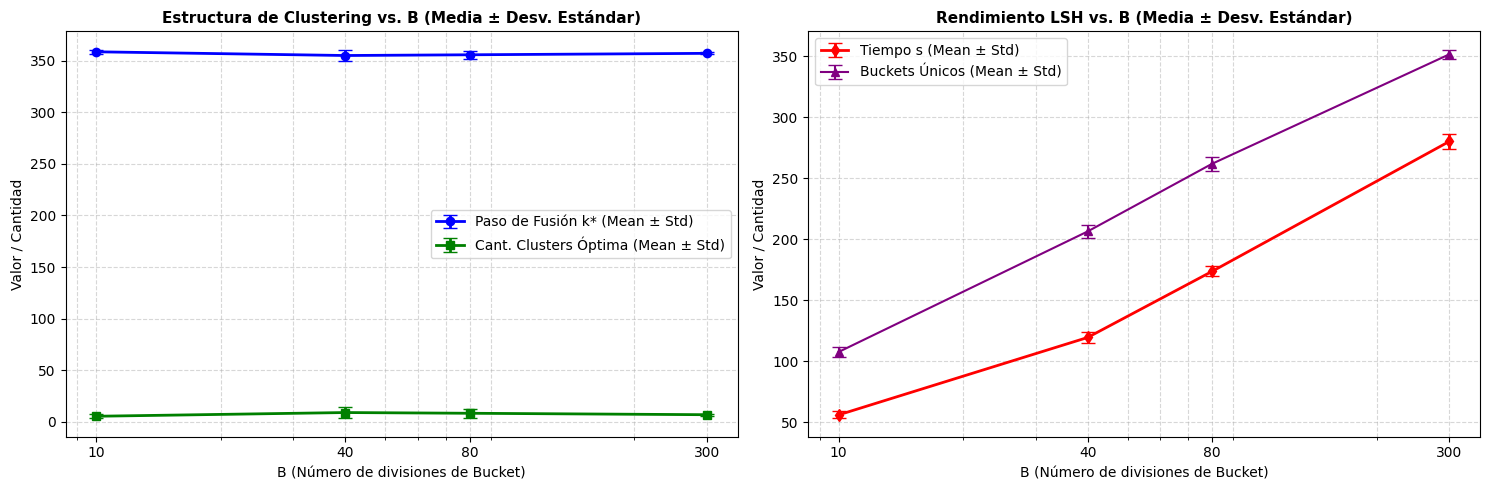

In [23]:
B_values_fao = [10, 40, 80, 300]
NUM_PROJ_SENSITIVITY_FAO = 5
REPS_PER_B_FAO = 10

sensitivity_results_fao = []

print("Evaluando análisis de sensibilidad sobre B (10 ejecuciones por valor)...")
# Semilla para reproducibilidad
np.random.seed(42)
random.seed(42)

for B_val in B_values_fao:
    print(f"Evaluando B = {B_val}...")
    temp_buckets = []
    temp_kstar = []
    temp_clusters = []
    temp_time = []
    
    for _ in range(REPS_PER_B_FAO):
        start_time = time.time()
        Z_B, _, _, _, bucket_ids = shclust_heap_dynamic(
            graphs,
            num_proj=NUM_PROJ_SENSITIVITY_FAO,
            B=B_val,
            epsilon=np.inf
        )
        elapsed = time.time() - start_time
        
        df_B = pd.DataFrame(
            Z_B,
            columns=[
                "cluster_i", "cluster_j", "dist", "q", "new_cluster_id",
                "new_bucket_id", "same_bucket", "global_mode"
            ]
        )
        k_star, _ = elbow_method(df_B["q"].values)
        num_clusters = df_B.shape[0] - k_star + 1
        unique_buckets = len(set(bucket_ids))
        
        temp_buckets.append(unique_buckets)
        temp_kstar.append(k_star)
        temp_clusters.append(num_clusters)
        temp_time.append(elapsed)
        
    sensitivity_results_fao.append({
        "B": B_val,
        
        "Buckets_Mean": np.mean(temp_buckets),
        "Buckets_Std": np.std(temp_buckets),
        "Buckets_Mode": calculate_mode(temp_buckets),
        
        "KStar_Mean": np.mean(temp_kstar),
        "KStar_Std": np.std(temp_kstar),
        "KStar_Mode": calculate_mode(temp_kstar),
        
        "Clusters_Mean": np.mean(temp_clusters),
        "Clusters_Std": np.std(temp_clusters),
        "Clusters_Mode": calculate_mode(temp_clusters),
        
        "Time_Mean": np.mean(temp_time),
        "Time_Std": np.std(temp_time),
        "Time_Mode": calculate_mode(temp_time)
    })

# Convertir a DataFrame y presentar reporte
df_sensitivity_fao = pd.DataFrame(sensitivity_results_fao)
print("\n=== REPORTE DE SENSIBILIDAD DE B SOBRE FAO (10 ejecuciones por valor) ===")
print(df_sensitivity_fao.to_string(index=False))

# ----------------------------------------------------
# Visualización de Sensibilidad FAO con Barras de Error
# ----------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Paso de Fusión y Número de Clusters
ax1.errorbar(df_sensitivity_fao["B"], df_sensitivity_fao["KStar_Mean"], yerr=df_sensitivity_fao["KStar_Std"], 
             marker='o', label="Paso de Fusión k* (Mean ± Std)", color="blue", linewidth=2, capsize=5)
ax1.errorbar(df_sensitivity_fao["B"], df_sensitivity_fao["Clusters_Mean"], yerr=df_sensitivity_fao["Clusters_Std"], 
             marker='s', label="Cant. Clusters Óptima (Mean ± Std)", color="green", linewidth=2, capsize=5)

ax1.set_xscale('log')
ax1.set_xticks(B_values_fao)
ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax1.set_title("Estructura de Clustering vs. B (Media ± Desv. Estándar)", fontsize=11, fontweight='bold')
ax1.set_xlabel("B (Número de divisiones de Bucket)")
ax1.set_ylabel("Valor / Cantidad")
ax1.grid(True, which="both", linestyle="--", alpha=0.5)
ax1.legend()

# Subplot 2: Tiempo de corrida y Buckets Únicos
ax2.errorbar(df_sensitivity_fao["B"], df_sensitivity_fao["Time_Mean"], yerr=df_sensitivity_fao["Time_Std"], 
             marker='d', color="red", linewidth=2, capsize=5, label="Tiempo s (Mean ± Std)")
ax2.errorbar(df_sensitivity_fao["B"], df_sensitivity_fao["Buckets_Mean"], yerr=df_sensitivity_fao["Buckets_Std"], 
             marker='^', color="purple", linewidth=1.5, capsize=5, label="Buckets Únicos (Mean ± Std)")
ax2.set_xscale('log')
ax2.set_xticks(B_values_fao)
ax2.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax2.set_title("Rendimiento LSH vs. B (Media ± Desv. Estándar)", fontsize=11, fontweight='bold')
ax2.set_xlabel("B (Número de divisiones de Bucket)")
ax2.set_ylabel("Valor / Cantidad")
ax2.grid(True, which="both", linestyle="--", alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()


In [24]:
print(df_sensitivity_fao.to_string(index=False))

  B  Buckets_Mean  Buckets_Std  Buckets_Mode  KStar_Mean  KStar_Std  KStar_Mode  Clusters_Mean  Clusters_Std  Clusters_Mode  Time_Mean  Time_Std  Time_Mode
 10         107.6     4.176123           107       358.7   1.900000         360            5.3      1.900000              4  55.998669  2.813181      60.19
 40         206.4     4.983974           207       355.1   5.575841         359            8.9      5.575841              5 119.460559  4.778166     116.54
 80         261.9     5.889822           254       355.8   4.118252         358            8.2      4.118252              6 173.676111  4.185230     169.13
300         351.7     3.689173           354       357.2   0.979796         357            6.8      0.979796              7 280.283274  6.078465     283.85
